In [1]:
import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib.colors as mplcolors
import matplotlib.ticker as ptick
import matplotlib.patches as patches
import matplotlib.patheffects as pe
from MyPlotRecipe.SharedX import ShareXaxis
from MyPlotRecipe.UniversalColor import UniversalColor
from MyPlotRecipe.legend_shadow import legend_shadow

import time
import spiceypy as spice
import JupiterMag as jm
from CSField import CSField

UC = UniversalColor()
UC.set_palette()

F = ShareXaxis()
F.fontsize = 23
F.fontname = 'Liberation Sans Narrow'
F.set_default()

jm.Internal.Config(Model='jrm33', Degree=18, CartesianIn=True,
                   CartesianOut=True)
jm.Con2020.Config(equation_type='integral')

spice.furnsh(
    '/Users/shin/Documents/Research/Jupiter/Codes/HST/kernel/cassMetaK.txt')
radii = spice.bodvrd("JUPITER", "RADII", 3)[1]
RJ_km = radii[0]
c = radii[2]
f = (RJ_km - c) / RJ_km

Importing Library
done


In [2]:
# ===========================================================
# CONSTANTS
# ===========================================================
MU0 = 4*np.pi*1E-7       # 真空中の透磁率 [H m-1]
AMU2KG = 1.66E-27        # [kg]
RJ = 71492.0E+3          # JUPITER RADIUS [m]


# ===========================================================
# CONFIGURE CSFIELD
# ===========================================================
csfield = CSField()
csfield.config(
    I_rho0=0.0,  # 8.3795
    i_phi0=4.91719E-5,
    b1=0.0,
)

In [73]:
# ===========================================================
# FIELD LINE TRACE (DAWN)
# ===========================================================
r0 = np.array([5.9, 9.4, 15.0, 26.0, 50.0, 75.0])*RJ  # [m]
theta0 = np.radians(89.99)        # Colatitude [rad]
phi0 = np.radians(360.0-112.0)   # East longitude [rad]

x0 = r0*np.sin(theta0)*np.cos(phi0)
y0 = r0*np.sin(theta0)*np.sin(phi0)
z0 = r0*np.cos(theta0)

Niter = 80000

ds0 = 1000000.0   # [m]
p = 1.2

result_arr0 = np.zeros((r0.size*2, 3, int(Niter/10)))

# 北半球
ns = -1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=6.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr0[j, 0, k] = x_cs/RJ
            result_arr0[j, 1, k] = y_cs/RJ
            result_arr0[j, 2, k] = z_cs/RJ
            # result_arr0[j, 0, k] = x/RJ
            # result_arr0[j, 1, k] = y/RJ
            # result_arr0[j, 2, k] = z/RJ
            k += 1

        # 終了条件
        if rs < (1.0*RJ+2000.0E+3):
            # ds = 5000.0     # [m]
            lon_gr, lat_gr, alt_gr = spice.recpgr('JUPITER',
                                                  np.array([x/1000.0,
                                                            y/1000.0,
                                                            z/1000.0]),
                                                  RJ_km,
                                                  f)
            if abs(alt_gr-1.0)*1000.0 <= 0.5*ds:
                print('End altitude [km]:', round(alt_gr, 2))
                break


# 南半球
ns = 1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=6.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr0[j+x0.size, 0, k] = x_cs/RJ
            result_arr0[j+x0.size, 1, k] = y_cs/RJ
            result_arr0[j+x0.size, 2, k] = z_cs/RJ
            # result_arr0[j+x0.size, 0, k] = x/RJ
            # result_arr0[j+x0.size, 1, k] = y/RJ
            # esult_arr0[j+x0.size, 2, k] = z/RJ
            k += 1

        # 終了条件
        if rs < (1.0*RJ+2000.0E+3):
            # ds = 5000.0     # [m]
            lon_gr, lat_gr, alt_gr = spice.recpgr('JUPITER',
                                                  np.array([x/1000.0,
                                                            y/1000.0,
                                                            z/1000.0]),
                                                  RJ_km,
                                                  f)
            if abs(alt_gr-1.0)*1000.0 <= 0.5*ds:
                print('End altitude [km]:', round(alt_gr, 2))
                break

End altitude [km]: 32.26
End altitude [km]: 15.05
End altitude [km]: -8.96
End altitude [km]: 30.34
End altitude [km]: -21.57
End altitude [km]: 43.91
End altitude [km]: -9.75
End altitude [km]: -47.52
End altitude [km]: 34.64
End altitude [km]: 55.07
End altitude [km]: -24.15
End altitude [km]: 13.25


In [4]:
# ===========================================================
# FIELD LINE TRACE (DUSK)
# ===========================================================
r0 = np.array([5.9, 9.4, 15.0, 26.0, 50.0])*RJ  # [m]
theta0 = np.radians(89.99)        # Colatitude [rad]
phi0 = np.radians(360.0-112.0)   # East longitude [rad]

x0 = r0*np.sin(theta0)*np.cos(phi0)
y0 = r0*np.sin(theta0)*np.sin(phi0)
z0 = r0*np.cos(theta0)

Niter = 70000

ds0 = 1000000.0   # [m]
p = 1.2

result_arr1 = np.zeros((r0.size*2, 3, int(Niter/10)))

# 北半球
ns = -1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=18.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr1[j, 0, k] = x_cs/RJ
            result_arr1[j, 1, k] = y_cs/RJ
            result_arr1[j, 2, k] = z_cs/RJ
            # result_arr1[j, 0, k] = x/RJ
            # result_arr1[j, 1, k] = y/RJ
            # esult_arr1[j, 2, k] = z/RJ
            k += 1

        # 終了条件
        if rs < (1.0*RJ+2000.0E+3):
            # ds = 5000.0     # [m]
            lon_gr, lat_gr, alt_gr = spice.recpgr('JUPITER',
                                                  np.array([x/1000.0,
                                                            y/1000.0,
                                                            z/1000.0]),
                                                  RJ_km,
                                                  f)
            if abs(alt_gr-1.0)*1000.0 <= 0.5*ds:
                print('End altitude [km]:', round(alt_gr, 2))
                break


# 南半球
ns = 1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=18.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr1[j+x0.size, 0, k] = x_cs/RJ
            result_arr1[j+x0.size, 1, k] = y_cs/RJ
            result_arr1[j+x0.size, 2, k] = z_cs/RJ
            # result_arr1[j+x0.size, 0, k] = x/RJ
            # result_arr1[j+x0.size, 1, k] = y/RJ
            # result_arr1[j+x0.size, 2, k] = z/RJ
            k += 1

        # 終了条件
        if rs < (1.0*RJ+2000.0E+3):
            # ds = 5000.0     # [m]
            lon_gr, lat_gr, alt_gr = spice.recpgr('JUPITER',
                                                  np.array([x/1000.0,
                                                            y/1000.0,
                                                            z/1000.0]),
                                                  RJ_km,
                                                  f)
            if abs(alt_gr-1.0)*1000.0 <= 0.5*ds:
                print('End altitude [km]:', round(alt_gr, 2), i)
                break

End altitude [km]: 32.26
End altitude [km]: 15.05
End altitude [km]: -8.96
End altitude [km]: 30.34
End altitude [km]: -21.57
End altitude [km]: -9.75 2736
End altitude [km]: -47.52 3871
End altitude [km]: 34.64 5038
End altitude [km]: 55.07 6495
End altitude [km]: -24.15 8873


In [ ]:
# ===========================================================
# FIELD LINE TRACE
# ===========================================================
r0 = 5.0*RJ  # [m]
# Colatitude [rad]
theta0 = np.radians(np.array([10.0, 20.0, 40.0, 60.0, 80.0]))
phi0 = np.radians(360.0-112.0)   # East longitude [rad]

x0 = r0*np.sin(theta0)*np.cos(phi0)
y0 = r0*np.sin(theta0)*np.sin(phi0)
z0 = r0*np.cos(theta0)

Niter = 70000

ds0 = 1000000.0   # [m]
p = 1.2

result_arr3 = np.zeros((x0.size, 3, int(Niter/10)))

# 北半球
ns = -1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=18.0)  # [T]
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr3[j, 0, k] = x_cs/RJ
            result_arr3[j, 1, k] = y_cs/RJ
            result_arr3[j, 2, k] = z_cs/RJ
            # result_arr3[j, 0, k] = x/RJ
            # result_arr3[j, 1, k] = y/RJ
            # result_arr3[j, 2, k] = z/RJ
            k += 1

        # 終了条件
        if rs < (1.0*RJ+2000.0E+3):
            # ds = 5000.0     # [m]
            lon_gr, lat_gr, alt_gr = spice.recpgr('JUPITER',
                                                  np.array([x/1000.0,
                                                            y/1000.0,
                                                            z/1000.0]),
                                                  RJ_km,
                                                  f)
            if abs(alt_gr-1.0)*1000.0 <= 0.5*ds:
                print('End altitude   [km]:', round(alt_gr, 2))
                print(
                    '--- latitude  [deg]:', round(np.mod(np.degrees(0.5*np.pi-theta), 360.0), 3))
                print(
                    '--- longitude [deg]:', round(np.mod(np.degrees(2*np.pi-phi), 360.0), 3))
                break

End altitude   [km]: 42.36
--- latitude  [deg]: 70.4
--- longitude [deg]: 169.085
End altitude   [km]: 15.36
--- latitude  [deg]: 66.009
--- longitude [deg]: 159.175
End altitude   [km]: 35.63
--- latitude  [deg]: 58.86
--- longitude [deg]: 146.59
End altitude   [km]: 14.84
--- latitude  [deg]: 53.669
--- longitude [deg]: 141.544
End altitude   [km]: -43.67
--- latitude  [deg]: 50.697
--- longitude [deg]: 140.618


In [69]:
# ===========================================================
# FIELD LINE TRACE (FROM IONOSPHERE)
# ===========================================================
r_cs = 1.001*RJ  # [m]
theta_cs = np.radians(np.array([18.0, 24.0, 45.0]))  # Colatitude [rad]
phi_cs = 60.0  # [rad]

x_cs0 = r_cs*np.sin(theta_cs)*np.cos(phi_cs)
y_cs0 = r_cs*np.sin(theta_cs)*np.sin(phi_cs)
z_cs0 = r_cs*np.cos(theta_cs)
print(np.sqrt(x_cs0**2+y_cs0**2+z_cs0**2)/RJ)

x0, y0, z0, = csfield._cs_2_sys3(x_cs0, y_cs0, z_cs0,
                                 np.sqrt(x_cs0**2+y_cs0**2), phi_cs)

print(np.sqrt(x0**2+y0**2+z0**2)/RJ)

Niter = 5000

ds0 = 1000000.0   # [m]
p = 1.2

result_arr_N = np.zeros((x0.size, 3, int(Niter/10)))

# 北半球から南半球へ
ns = 1     # -1: north; 1: south
start = time.time()
for j in range(x0.size):
    k = 0
    x, y, z = x0[j], y0[j], z0[j]
    for i in range(Niter):
        Bx0, By0, Bz0 = jm.Internal.Field(x/RJ, y/RJ, z/RJ)       # [nT]
        Bx1, By1, Bz1 = csfield.magnetic_field(x/RJ, y/RJ, z/RJ,
                                               MLT=18.0)  # [T]
        Bx1, By1, Bz1 = 0.0, 0.0, 0.0,
        Bx = (Bx0*1E-9)+Bx1     # [T]
        By = (By0*1E-9)+By1     # [T]
        Bz = (Bz0*1E-9)+Bz1     # [T]
        B0 = math.sqrt(Bx[0]**2+By[0]**2+Bz[0]**2)      # [T]

        ds = ds0/(np.log10(B0*1E+9))**p      # [m]

        # 座標更新 (x, y, z)
        x += (ds*Bx[0]/B0)*ns
        y += (ds*By[0]/B0)*ns
        z += (ds*Bz[0]/B0)*ns

        # if i % 200 == 0:
        #     print('ds [km]:', ds/1000.0)

        # 座標更新 (r, theta, phi)
        rs = math.sqrt(x**2 + y**2 + z**2)
        theta = math.acos(z/rs)
        phi = math.atan2(y, x)

        if i % 10 == 0:
            x_cs, y_cs, z_cs = csfield._sys3_2_cs(x, y, z)
            result_arr_N[j, 0, k] = x_cs/RJ
            result_arr_N[j, 1, k] = y_cs/RJ
            result_arr_N[j, 2, k] = z_cs/RJ
            # result_arr_N[j, 0, k] = x/RJ
            # result_arr_N[j, 1, k] = y/RJ
            # result_arr_N[j, 2, k] = z/RJ
            k += 1

        # 終了条件 (北の外側境界)
        if z > 30.0*RJ:
            print('North edge [km]:')
            break
        # 終了条件 (水平距離の外側境界)
        if math.sqrt(x**2+y**2) > 30.0*RJ:
            print('Horizontal edge')
            break

    print(rs/RJ, y/RJ)

[1.001 1.001 1.001]
[1.001 1.001 1.001]
17.545923810225315 2.4035136770804755
15.636720762772589 1.8476700643049564
0.0004509867106110889 0.0004371770658636105


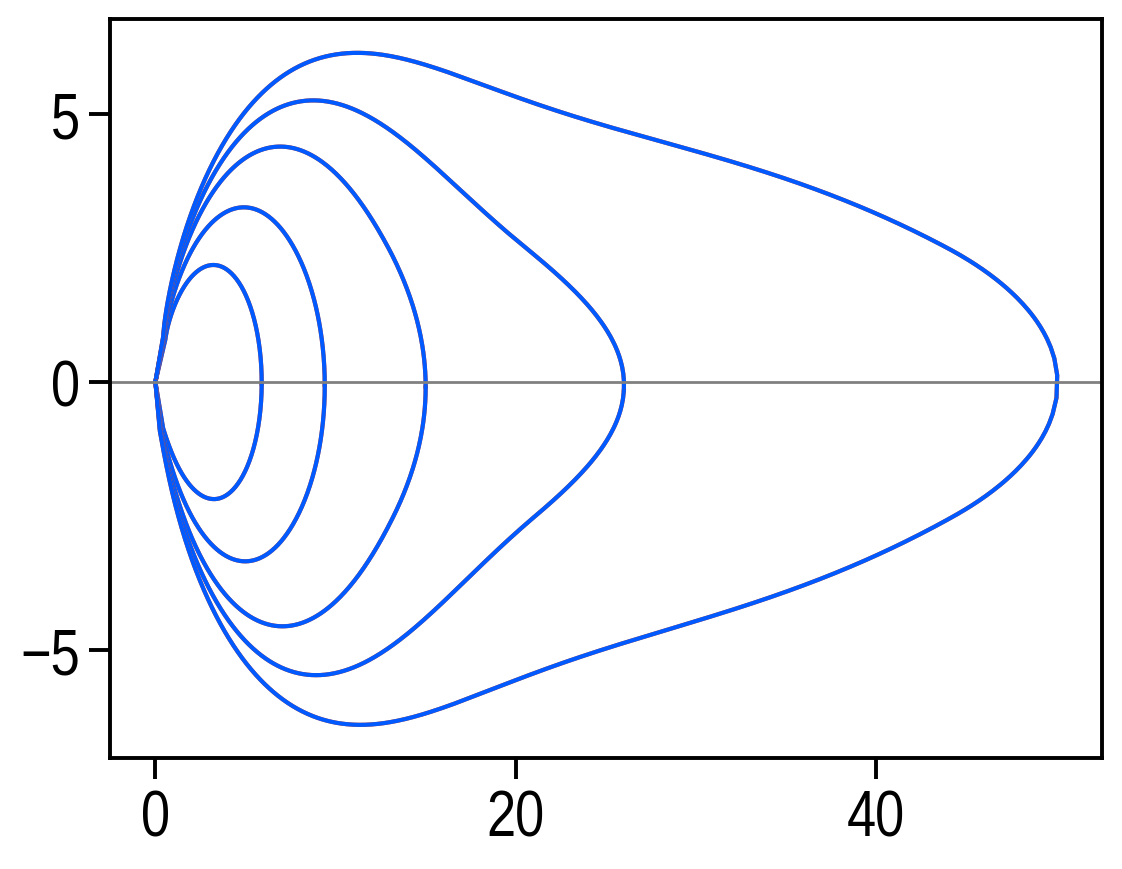

In [7]:
fig, ax = plt.subplots(dpi=200)

for i in range(result_arr0.shape[0]):
    rho_cs = np.sqrt(result_arr0[i, 0, :]**2+result_arr0[i, 1, :]**2)
    ax.plot(rho_cs, result_arr0[i, 2, :], color=UC.red)
    rho_cs = np.sqrt(result_arr1[i, 0, :]**2+result_arr1[i, 1, :]**2)
    ax.plot(rho_cs, result_arr1[i, 2, :], color=UC.blue)
ax.axhline(y=0.0, color='gray', linewidth=1.0)

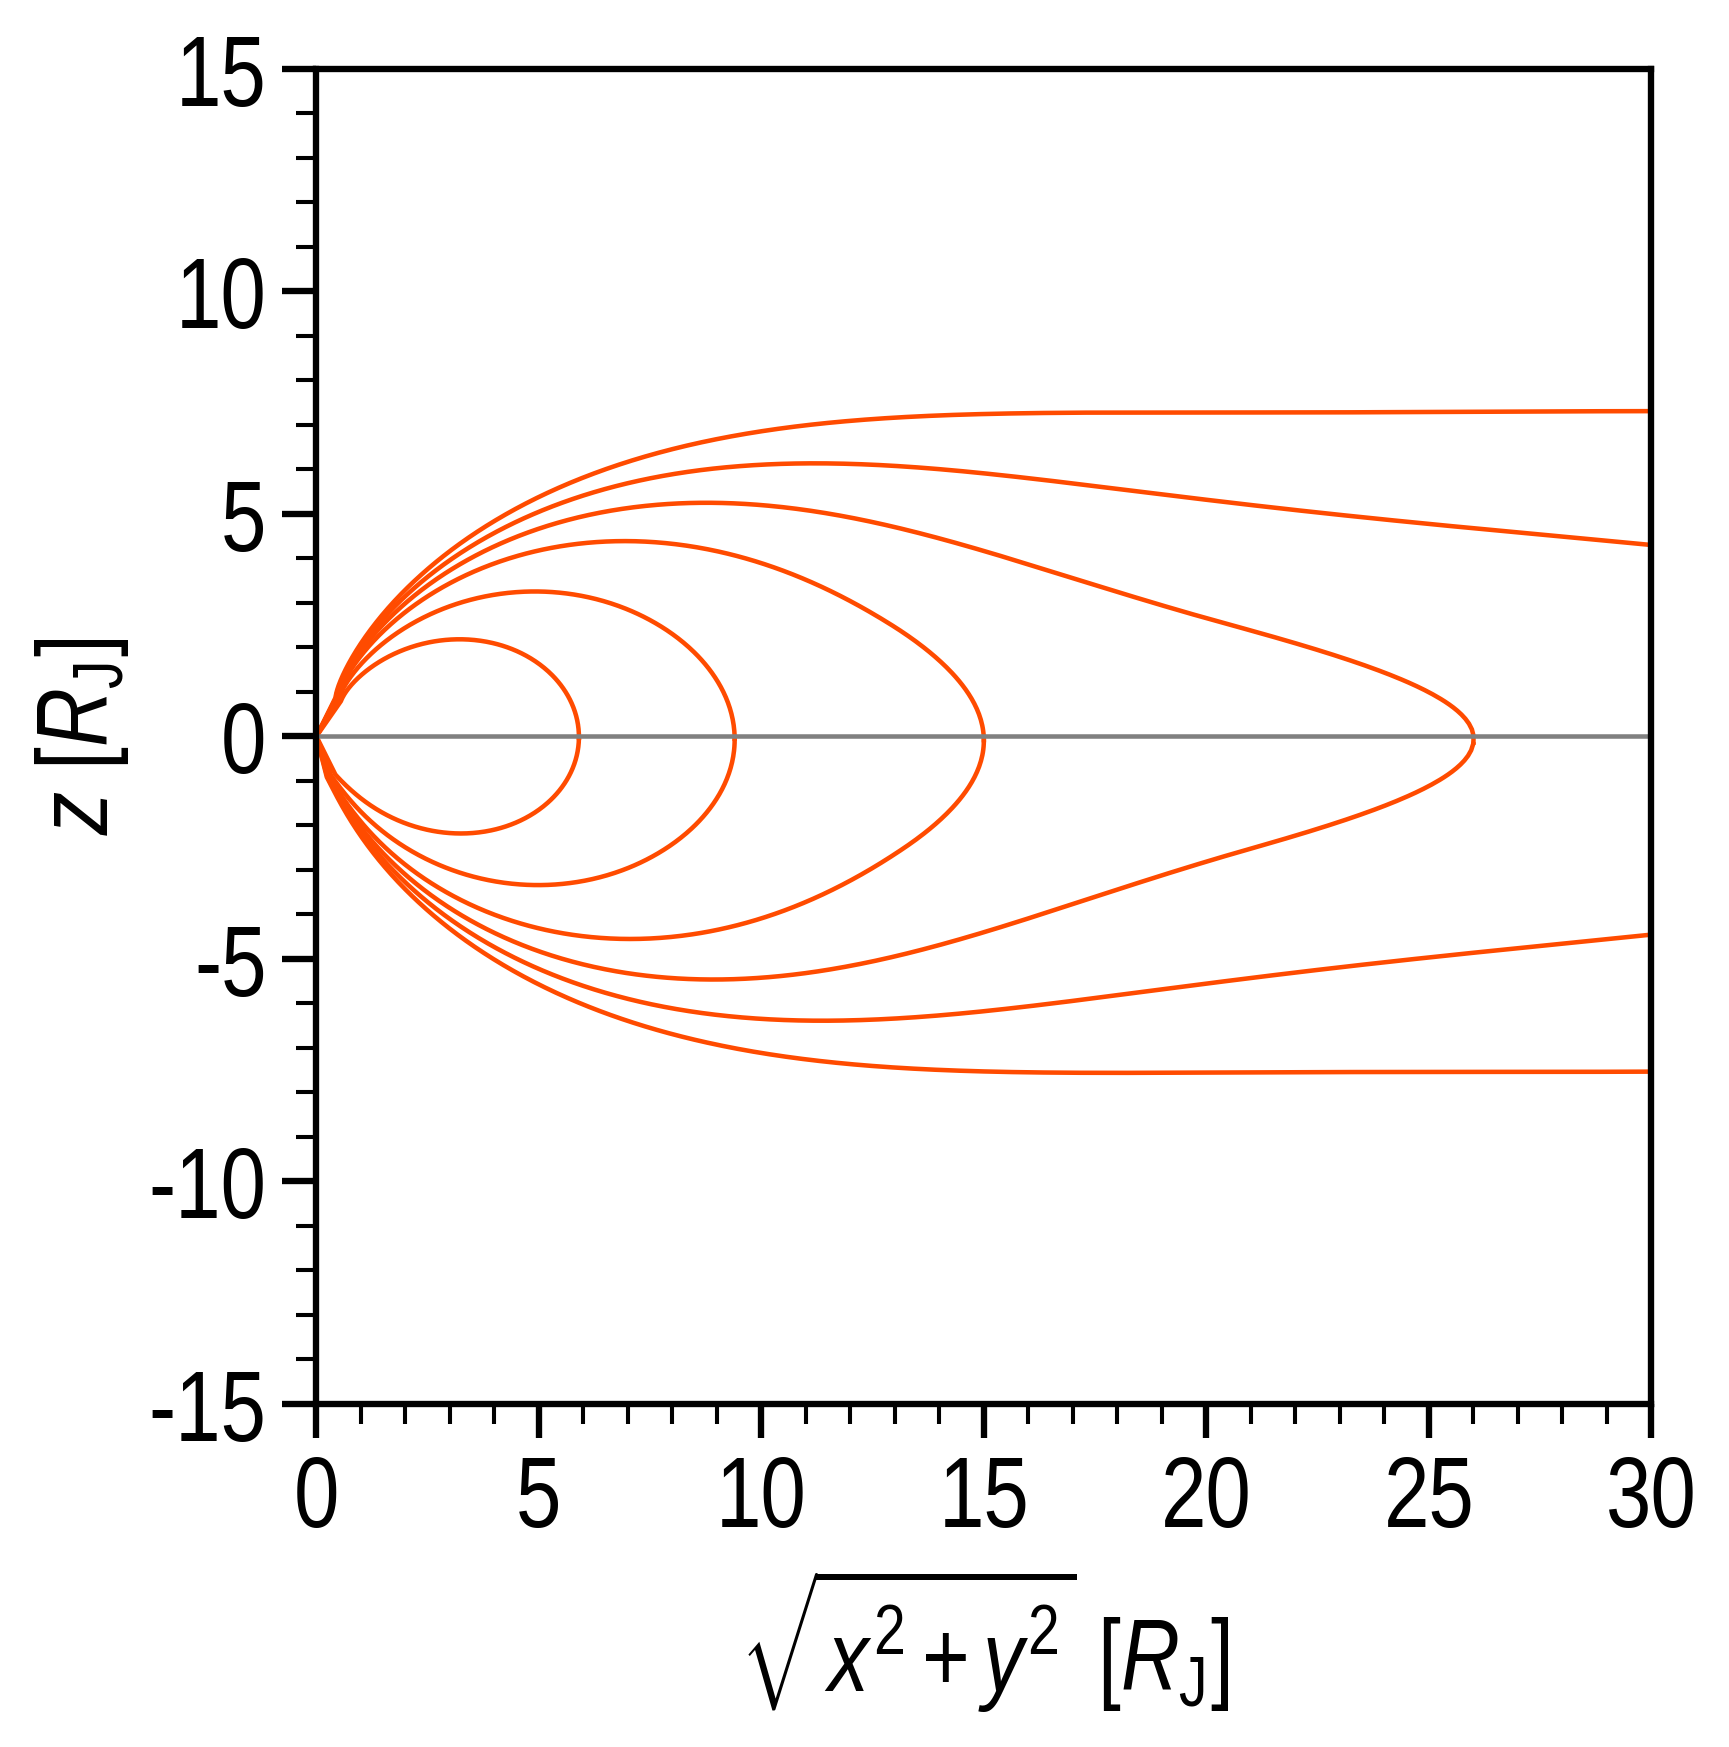

In [74]:
F = ShareXaxis()
F.fontsize = 22
F.fontname = 'Liberation Sans Narrow'

F.set_figparams(nrows=1, figsize=(5.5, 5.5), dpi='XL')
F.initialize()

F.ax.set_aspect('equal')

F.set_xaxis(label=r'$\sqrt{x^2+y^2}$ [$R_{\rm J}$]',
            min=0.0, max=30.0,
            ticks=np.arange(0, 30+1, 5),
            ticklabels=np.arange(0, 30+1, 5),
            minor_num=5)
F.set_yaxis(ax_idx=0,
            label=r'$z$ [$R_{\rm J}$]',
            min=-15.0, max=15.0,
            ticks=np.arange(-15, 15+1, 5),
            ticklabels=np.arange(-15, 15+1, 5, dtype=int),
            minor_num=5,)

for i in range(result_arr0.shape[0]):
    rho_cs = np.sqrt(result_arr0[i, 0, :]**2+result_arr0[i, 1, :]**2)
    F.ax.plot(rho_cs, result_arr0[i, 2, :], linewidth=1.0, color=UC.red)
"""for i in range(result_arr_N.shape[0]):
    rho_cs = np.sqrt(result_arr_N[i, 0, :]**2+result_arr_N[i, 1, :]**2)
    F.ax.plot(rho_cs, result_arr_N[i, 2, :], linewidth=1.0, color='k')"""
"""for i in range(result_arr3.shape[0]):
    rho_cs = np.sqrt(result_arr3[i, 0, :]**2+result_arr3[i, 1, :]**2)
    F.ax.plot(rho_cs, result_arr3[i, 2, :], linewidth=1.0, color=UC.blue)"""
F.ax.axhline(y=0.0, color='gray', linewidth=1.0)